In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

In [3]:
df = pd.read_csv("dataset/ad.data", header=None, skipinitialspace=True, na_values="?")

In [4]:
df.shape

(3279, 1559)

In [5]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,1549,1550,1551,1552,1553,1554,1555,1556,1557,1558
0,125.0,125.0,1.0000,1.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ad.
1,57.0,468.0,8.2105,1.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ad.
2,33.0,230.0,6.9696,1.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ad.
3,60.0,468.0,7.8000,1.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ad.
4,60.0,468.0,7.8000,1.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,ad.


In [6]:
df.tail()

,0,1,2,3,4,5,6,7,8,9,...,1549,1550,1551,1552,1553,1554,1555,1556,1557,1558
3274,170.0,94.0,0.5529,0.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,nonad.
3275,101.0,140.0,1.3861,1.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,nonad.
3276,23.0,120.0,5.2173,1.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,nonad.
3277,NaN,NaN,NaN,1.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,nonad.
3278,40.0,40.0,1.0000,1.0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,nonad.


In [7]:
df.shape

(3279, 1559)

In [8]:
display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values
}))

,Column,Data Type
0,0,float64
1,1,float64
2,2,float64
3,3,float64
4,4,int64
...,...,...
1554,1554,int64
1555,1555,int64
1556,1556,int64
1557,1557,int64


In [9]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 3279 entries, 0 to 3278
Data columns (total 1559 columns):
 #     Column  Dtype  
---    ------  -----  
 0     0       float64
 1     1       float64
 2     2       float64
 3     3       float64
 4     4       int64  
 5     5       int64  
 6     6       int64  
 7     7       int64  
 8     8       int64  
 9     9       int64  
 10    10      int64  
 11    11      int64  
 12    12      int64  
 13    13      int64  
 14    14      int64  
 15    15      int64  
 16    16      int64  
 17    17      int64  
 18    18      int64  
 19    19      int64  
 20    20      int64  
 21    21      int64  
 22    22      int64  
 23    23      int64  
 24    24      int64  
 25    25      int64  
 26    26      int64  
 27    27      int64  
 28    28      int64  
 29    29      int64  
 30    30      int64  
 31    31      int64  
 32    32      int64  
 33    33      int64  
 34    34      int64  
 35    35      int64  
 36    36      int64  
 37  

In [10]:
memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"Approximate memory used by dataset: {memory_mb:.3f} MB")

Approximate memory used by dataset: 39.147 MB


In [11]:
missing_value_in_each_column=df.isna().sum()
print("Missing values in each column:\n", missing_value_in_each_column)


Missing values in each column:
 0       903
1       901
2       910
3        15
4         0
       ... 
1554      0
1555      0
1556      0
1557      0
1558      0
Length: 1559, dtype: int64


In [12]:
total_missing_values = missing_value_in_each_column.sum()
print("Total missing values in the dataset:", total_missing_values)
missing_pct = df.isna().mean().mul(100)
missing_pct = missing_pct[missing_pct > 0]
print("Percentage of missing values in each column:\n", missing_pct)

Total missing values in the dataset: 2729
Percentage of missing values in each column:
 0    27.538884
1    27.477890
2    27.752364
3     0.457457
dtype: float64


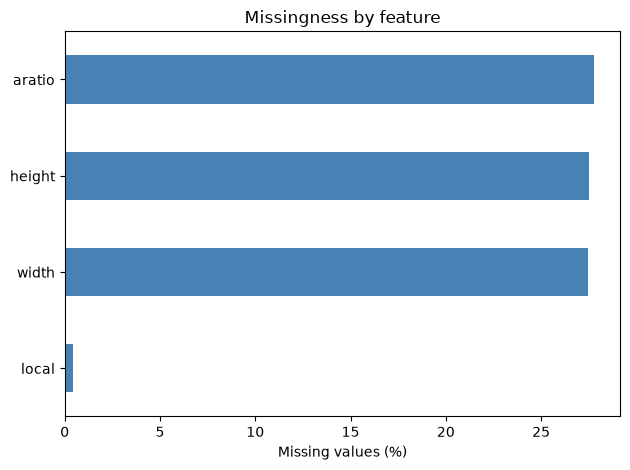

In [13]:
labels = {0: "height", 1: "width", 2: "aratio", 3: "local"}
missing_pct.index = [labels.get(col, str(col)) for col in missing_pct.index]

missing_pct.sort_values().plot(kind="barh", color="steelblue")
plt.xlabel("Missing values (%)")
plt.title("Missingness by feature")
plt.tight_layout()
plt.show()

In [14]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print("Percentage of duplicate rows:",
      round((duplicate_count / len(df)) * 100, 2), "%")

Number of duplicate rows: 856
Percentage of duplicate rows: 26.11 %


In [15]:
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (2423, 1559)


In [16]:
unique_table = pd.DataFrame({
    "Column": df.columns,
    "Unique Values": [df[col].nunique() for col in df.columns]
}).sort_values("Unique Values")

display(unique_table)

,Column,Unique Values
1553,1553,2
17,17,2
18,18,2
19,19,2
20,20,2
...,...,...
31,31,2
1552,1552,2
0,0,220
1,1,277


In [17]:
numerical_summary = df.describe().T
display(numerical_summary.round(2))

,count,mean,std,min,25%,50%,75%,max
0,1936.0,67.68,56.41,1.0,30.00,60.00,90.00,640.0
1,1940.0,160.80,126.79,1.0,87.75,115.00,200.00,640.0
2,1931.0,3.73,4.34,0.0,1.09,2.27,5.59,60.0
3,2412.0,0.73,0.45,0.0,0.00,1.00,1.00,1.0
4,2423.0,0.00,0.06,0.0,0.00,0.00,0.00,1.0
...,...,...,...,...,...,...,...,...
1553,2423.0,0.01,0.07,0.0,0.00,0.00,0.00,1.0
1554,2423.0,0.02,0.13,0.0,0.00,0.00,0.00,1.0
1555,2423.0,0.02,0.13,0.0,0.00,0.00,0.00,1.0
1556,2423.0,0.01,0.11,0.0,0.00,0.00,0.00,1.0


In [18]:
categorical_summary = df.describe(include=["object"]).T
display(categorical_summary)

C:\Users\prakhar\AppData\Local\Temp\ipykernel_18196\2223778491.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_summary = df.describe(include=["object"]).T


,count,unique,top,freq
1558,2423,2,nonad.,2037


In [ ]:
features = df.iloc[:, :-1]

unique_counts = features.nunique(dropna=False)
unique_fraction = unique_counts / len(df)

possible_ids = unique_fraction[unique_fraction > 0.9]
print(possible_ids)

Series([], dtype: float64)


In [20]:
for col in possible_ids.index:
    print(f"\nColumn {col}:")
    print(df[col].head(10).tolist())

1558
nonad.    2037
ad.        386
Name: count, dtype: int64


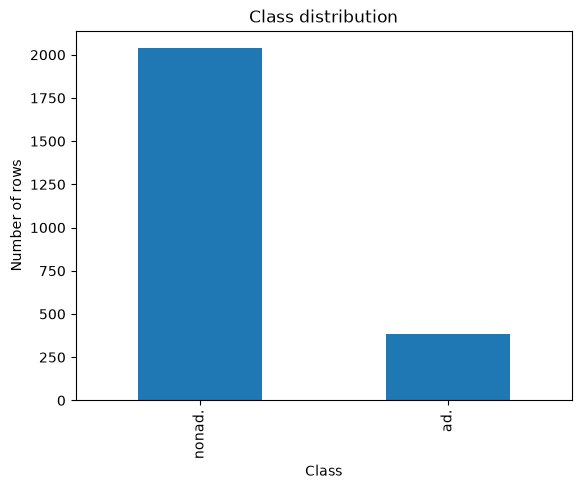

In [21]:
target = df.columns[-1]
counts = df[target].value_counts(dropna=False)

print(counts)
counts.plot(kind="bar", xlabel="Class", ylabel="Number of rows",
            title="Class distribution")
plt.show()

,Q1,Median (Q2),Q3,IQR,Quartile deviation,Lower bound,Upper bound,Probable outliers (count)
height,30.00,60.00,90.00,60.00,30.00,-60.00,180.00,76
width,87.75,115.00,200.00,112.25,56.12,-80.62,368.38,232
aratio,1.09,2.27,5.59,4.50,2.25,-5.65,12.33,18


C:\Users\prakhar\AppData\Local\Temp\ipykernel_18196\3720295727.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(numeric[column].dropna(), vert=False)
C:\Users\prakhar\AppData\Local\Temp\ipykernel_18196\3720295727.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(numeric[column].dropna(), vert=False)
C:\Users\prakhar\AppData\Local\Temp\ipykernel_18196\3720295727.py:34: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(numeric[column].dropna(), vert=False)


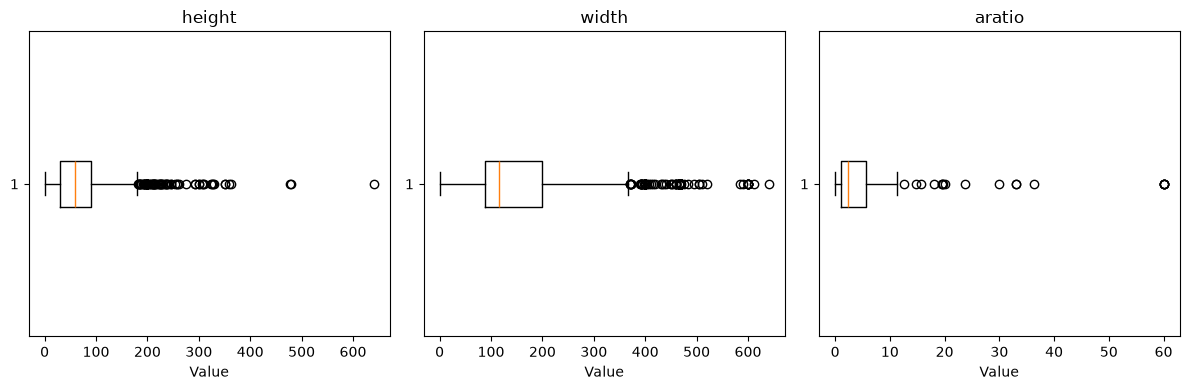

In [24]:
numeric = df.iloc[:, :3].apply(pd.to_numeric, errors="coerce")
numeric.columns = ["height", "width", "aratio"]

# Quartile summary
q1 = numeric.quantile(0.25)
q2 = numeric.quantile(0.50)
q3 = numeric.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

probable_outlier_count = (
    (numeric.lt(lower_bound)) | (numeric.gt(upper_bound))
).sum()

quartile_table = pd.DataFrame({
    "Q1": q1,
    "Median (Q2)": q2,
    "Q3": q3,
    "IQR": iqr,
    "Quartile deviation": iqr / 2,
    "Lower bound": lower_bound,
    "Upper bound": upper_bound,
    "Probable outliers (count)": probable_outlier_count
})

display(quartile_table.round(2))

# Boxplot for each numeric feature
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, column in zip(axes, numeric.columns):
    ax.boxplot(numeric[column].dropna(), vert=False)
    ax.set_title(column)
    ax.set_xlabel("Value")

plt.tight_layout()
plt.show()

In [25]:
numeric = df.iloc[:, :3].apply(pd.to_numeric, errors="coerce")
numeric.columns = ["height", "width", "aratio"]

target = df.iloc[:, -1].astype("string").str.strip().str.rstrip(".")

q1 = numeric.quantile(0.25)
q3 = numeric.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

summary = pd.DataFrame({
    "Count": numeric.count(),
    "Missing": numeric.isna().sum(),
    "Mean": numeric.mean(),
    "Std": numeric.std(),
    "Min": numeric.min(),
    "Q1": q1,
    "Median": numeric.median(),
    "Q3": q3,
    "Max": numeric.max(),
    "IQR": iqr,
    "Quartile deviation": iqr / 2,
    "Lower bound": lower,
    "Upper bound": upper,
    "Potential outliers": (
        numeric.lt(lower) | numeric.gt(upper)
    ).sum()
})

display(summary.round(2))

,Count,Missing,Mean,Std,Min,Q1,Median,Q3,Max,IQR,Quartile deviation,Lower bound,Upper bound,Potential outliers
height,1936,487,67.68,56.41,1.0,30.00,60.00,90.00,640.0,60.00,30.00,-60.00,180.00,76
width,1940,483,160.80,126.79,1.0,87.75,115.00,200.00,640.0,112.25,56.12,-80.62,368.38,232
aratio,1931,492,3.73,4.34,0.0,1.09,2.27,5.59,60.0,4.50,2.25,-5.65,12.33,18


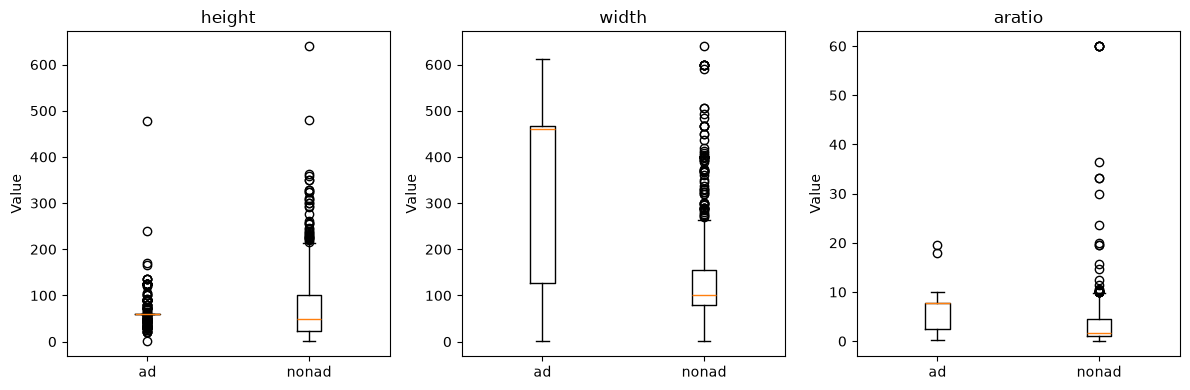

In [26]:
classes = sorted(target.dropna().unique())

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, column in zip(axes, numeric.columns):
    values_by_class = [
        numeric.loc[target == label, column].dropna()
        for label in classes
    ]

    ax.boxplot(values_by_class)
    ax.set_xticks(range(1, len(classes) + 1))
    ax.set_xticklabels(classes)
    ax.set_title(column)
    ax.set_ylabel("Value")

plt.tight_layout()
plt.show()

In [30]:
from pathlib import Path
import re
import pandas as pd
import matplotlib.pyplot as plt

# Read attribute names from ad.names
names_path = Path("dataset") / "ad.names"
attribute_names = []

for line in names_path.read_text(encoding="latin-1").splitlines():
    match = re.match(r"^\s*(.+?):\s*(?:continuous|0,1)\.", line)
    if match:
        attribute_names.append(match.group(1).strip())

# The last dataframe column is the target; the names file lists predictors
if len(attribute_names) != df.shape[1] - 1:
    raise ValueError(
        f"Found {len(attribute_names)} feature names but "
        f"{df.shape[1] - 1} predictor columns in df."
    )

target = df.iloc[:, -1].astype("string").str.strip().str.rstrip(".")
binary = df.iloc[:, 3:-1].apply(pd.to_numeric, errors="coerce")
binary.columns = attribute_names[3:]

,Count when present,Ad rate when present (%),Count when absent,Ad rate when absent (%),Rate difference (percentage points)
ancurl*http+www,67,98.51,2356,13.58,84.93
ancurl*click+runid,26,100.00,2397,15.02,84.98
url*ng,29,100.00,2394,14.91,85.09
ancurl*groupid+1,31,100.00,2392,14.84,85.16
ancurl*1+familyid,31,100.00,2392,14.84,85.16
ancurl*adclick,32,100.00,2391,14.81,85.19
ancurl*cid,34,100.00,2389,14.73,85.27
ancurl*tagvalues,43,100.00,2380,14.41,85.59
ancurl*groupid,43,100.00,2380,14.41,85.59
ancurl*familyid,43,100.00,2380,14.41,85.59


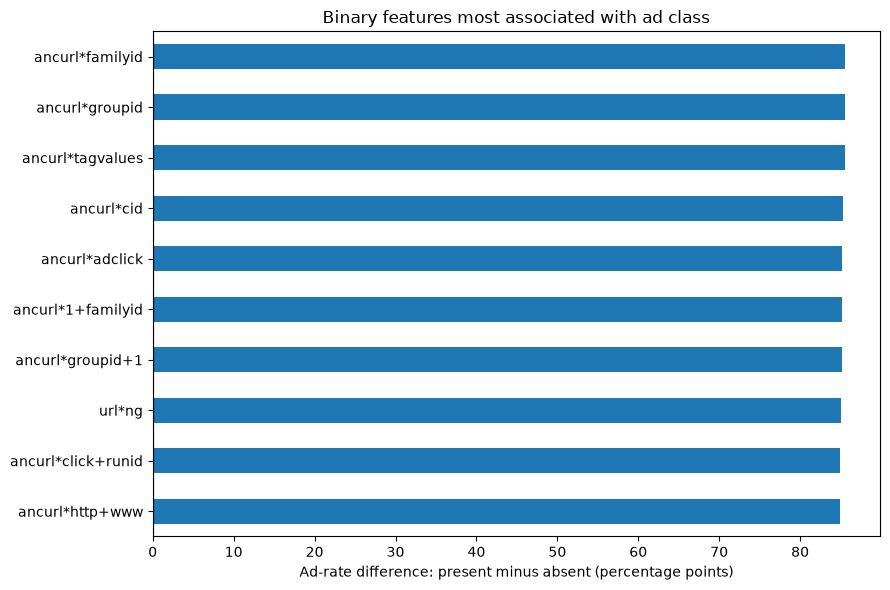

In [31]:
is_ad = target.eq("ad").astype(int)

present = binary.eq(1)
absent = binary.eq(0)

n_present = present.sum()
n_absent = absent.sum()

rate_present = present.mul(is_ad, axis=0).sum() / n_present
rate_absent = absent.mul(is_ad, axis=0).sum() / n_absent

comparison = pd.DataFrame({
    "Count when present": n_present,
    "Ad rate when present (%)": rate_present * 100,
    "Count when absent": n_absent,
    "Ad rate when absent (%)": rate_absent * 100,
})

comparison["Rate difference (percentage points)"] = (
    comparison["Ad rate when present (%)"]
    - comparison["Ad rate when absent (%)"]
)

# Keep features with at least 20 observed 0s and 20 observed 1s
eligible = (
    (comparison["Count when present"] >= 20) &
    (comparison["Count when absent"] >= 20)
)
comparison = comparison.loc[eligible]

top_features = comparison[
    "Rate difference (percentage points)"
].abs().nlargest(10).index

top_comparison = comparison.loc[top_features].sort_values(
    "Rate difference (percentage points)"
)

display(top_comparison.round(2))

top_comparison["Rate difference (percentage points)"].plot(
    kind="barh", figsize=(9, 6)
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Ad-rate difference: present minus absent (percentage points)")
plt.title("Binary features most associated with ad class")
plt.tight_layout()
plt.show()

Rows shown: 1931


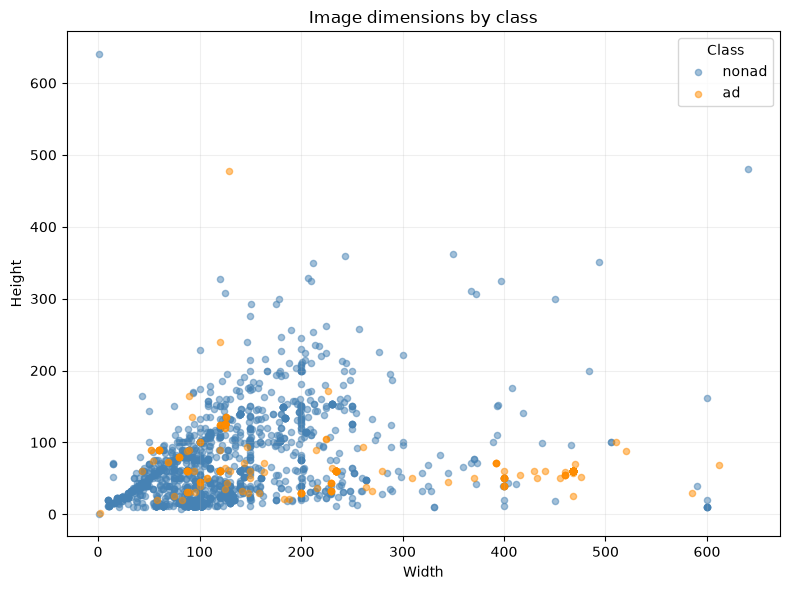

In [32]:


numeric = df.iloc[:, :3].apply(pd.to_numeric, errors="coerce")
numeric.columns = ["height", "width", "aratio"]
target = df.iloc[:, -1].astype("string").str.strip().str.rstrip(".")

plot_data = pd.DataFrame({
    "width": numeric["width"],
    "height": numeric["height"],
    "class": target
}).dropna()

# Dimensions should be positive; exclude non-positive values from this plot
plot_data = plot_data[
    (plot_data["width"] > 0) & (plot_data["height"] > 0)
]

print(f"Rows shown: {len(plot_data)}")

fig, ax = plt.subplots(figsize=(8, 6))

# Draw non-ads first so ads remain visible where points overlap
for label, color in [("nonad", "steelblue"), ("ad", "darkorange")]:
    subset = plot_data[plot_data["class"] == label]
    ax.scatter(
        subset["width"],
        subset["height"],
        label=label,
        color=color,
        alpha=0.5,
        s=20
    )

ax.set_xlabel("Width")
ax.set_ylabel("Height")
ax.set_title("Image dimensions by class")
ax.legend(title="Class")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()